# Main Text Figure 1

In [1]:
import xarray as xr
import xagg as xa
from xhistogram import xarray as xhist
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy import stats as sstats
import os
import re
import glob
import string
import warnings
from tqdm.notebook import tqdm
from matplotlib import pyplot as plt
import matplotlib as mpl
from matplotlib import patches as mpatches
from cartopy import crs as ccrs
import cmocean

from funcs_support import get_filepaths,get_params,utility_save,utility_print,load_shp
from funcs_readregs import coeffs_mortality,coeffs_gdppc,coeffs_payroll
from funcs_plot import plot_map
dir_list = get_params()

params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','popwght':False},
               'gdppc':{'varname':'tassumpoly','geo_typ':'adm1','popwght':True},
               'payroll':{'varname':'days90plus','geo_typ':'adm2-us','popwght':True}}

nsamples = 1000
rng = np.random.default_rng()

extra_fonts = {'lato':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Regular.ttf'),
 'lato-bold':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Bold.ttf')}
subplot_lettering = string.ascii_uppercase # string.ascii_lowercase

In [2]:
from distributed import Client

# Start dask client
client = Client()
display(client)

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /node/crhtc76.hpc.ucar.edu/48637/proxy/8787/status,
Dashboard: /node/crhtc76.hpc.ucar.edu/48637/proxy/8787/status,Workers: 6
Total threads: 18,Total memory: 144.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:38523,Workers: 0
Dashboard: /node/crhtc76.hpc.ucar.edu/48637/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:45895,Total threads: 3
Dashboard: /node/crhtc76.hpc.ucar.edu/48637/proxy/44587/status,Memory: 24.00 GiB
Nanny: tcp://127.0.0.1:34321,


In [3]:
def load_dmgfs(proc,load_kwargs = {},
              rng = rng,
              nsamples = nsamples):
    ''' Load MC'ed damage function, sampled at temperatures Tref

    Parameters
    ---------------
    proc : str
        Name of impact variable

    load_kwargs : dict
        Piped into `coeffs_*()`

    rng : numpy random generator

    nsamples : int
        Number of MC samples of VCV to use

    Returns
    ---------------
    dmgf : xr.DataArray
        `Tref` x `proj_base` x `sidx` datarray giving 
        coefficients at temperatures `Tref`


    '''
    
    # Load regression coefficients
    if proc == 'gdppc':
        coeffs,vcv = coeffs_gdppc(**load_kwargs)
    elif proc == 'mortality':
        coeffs,vcv = coeffs_mortality(**load_kwargs)
    elif proc == 'payroll':
        coeffs,vcv = coeffs_payroll(**load_kwargs)
    else:
        raise KeyError()

    coeffs = coeffs.dropna('proj_base',how='all')
    if 'proj_base_1' in vcv:
        vcv.dropna('proj_base_1').dropna('proj_base_2')
    else:
        vcv = vcv.dropna('proj_base',how='all')

    # Get MC samples of coefficients
    if 'proj_base_1' in vcv:
        # If jointly estimated across parameters
        coeffs_tmp = coeffs.coeffs.stack(predproj = ['pred','proj_base'])
        vcv_tmp = vcv.vcv.stack(predproj_1 = ['pred_1','proj_base_1'],
                                 predproj_2 = ['pred_2','proj_base_2'])
        
        coeffs_mvn = rng.multivariate_normal(coeffs_tmp,
                                             vcv_tmp,
                                             size=nsamples)
        
        coeffs_mvn = xr.DataArray(coeffs_mvn,
                                  dims = ['sidx','predproj'],
                                  coords = {'predproj':coeffs_tmp.predproj})
        coeffs_mvn = coeffs_mvn.unstack('predproj')
    else:
        # If separate fit for each proj_base
        coeffs_mvn = xr.apply_ufunc(rng.multivariate_normal,
                                   coeffs.coeffs,
                                   vcv.vcv,
                                   input_core_dims = [['pred'],['pred_1','pred_2']],
                                   output_core_dims = [['sidx','pred']],
                                   kwargs = {'size':nsamples},
                                           dask = 'parallelized',
                                           dask_gufunc_kwargs = {'output_sizes':{'sidx':nsamples}},
                                   vectorize=True)

    if np.any(['sumpoly' in k for k in coeffs_mvn.pred.values]):
        ts = np.arange(-20,51)
        var_stem = 'tassumpoly_'
        poly_degs = [int(re.split(var_stem,v)[-1]) for v in coeffs_mvn.pred.values if var_stem in v]
        t_vals = xr.DataArray(np.vstack([ts**k for k in poly_degs]),
                     dims = ['pred','bin_c'],
                     coords = {'pred':[v for v in coeffs_mvn.pred.values if var_stem in v],
                               'bin_c':ts})
    
        # Get damage function
        dmgf = (coeffs_mvn*t_vals).sum('pred')
        
        if proc == 'mortality':
            # Normalize over lowest value
            dmgf = dmgf - dmgf.sel(bin_c = slice(10,30)).min('bin_c')
        elif proc == 'gdppc':
            # Normalize over highest value
            dmgf = dmgf - dmgf.sel(bin_c = slice(10,30)).max('bin_c')
            #dmgf = dmgf - dmgf.sel(bin_c = 13)
        
        dmgf = dmgf.rename({'bin_c':'Tref'})
    elif 'bin' in coeffs_mvn.pred.values[0]:
        # Constructing the single-bin version
        dmgf = xr.apply_ufunc(rng.normal,
                   coeffs.isel(pred=0),
                   vcv.vcv.isel(pred_1 = 0,pred_2 = 0),
                   output_core_dims = [['sidx']],
                   vectorize=True,
                   kwargs = {'size':nsamples})
        
        dmgf = dmgf.expand_dims({'bin_f':np.arange(float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1]),
                                             125,5)})
        
        dmgf = xr.concat([xr.zeros_like(dmgf.isel(bin_f=0,drop=True)).expand_dims({'bin_f':np.arange(float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1])-20,
                                                                                   float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1]),
                                                                                   5)}),
                          dmgf],
                         dim='bin_f')
    
        dmgf = dmgf.rename({'bin_f':'Tref'}).coeffs
    elif 'days' in coeffs_mvn.pred.values[0]:
        dmgf = coeffs_mvn.expand_dims({'bin_f':np.arange(92.5, 125,5)}).isel(pred=0)
        dmgf = xr.concat([xr.zeros_like(dmgf.isel(bin_f=0,drop=True)).expand_dims({'bin_f':np.arange(92.5-20,
                                                                                           92.5,
                                                                                           5)}),
                                  dmgf],
                                 dim='bin_f')
        dmgf = dmgf.rename({'bin_f':'Tref'})

    return dmgf

In [4]:
# Load mortality damage function
dmgf = load_dmgfs('mortality')
dmgf = dmgf.mean('sidx')
dmgf = dmgf.rename({'Tref':'binC'})

In [5]:
# Get in-sample data that's feeding the regressions
reg_data = pd.read_csv(dir_list['proc']+'reg_inputs/mortality/reginputs_mortality_025deg.csv',low_memory=False,index_col=0)
reg_data = reg_data.query('iso != "IND"')
reg_data = reg_data.query('agegroup == "total"')
reg_data = reg_data.query('obs_mod == "GMFD"')
reg_data['regid'] = reg_data['iso']+reg_data['adm1_id']+reg_data['adm2_id']

In [6]:
gdf = {}
# Get regression input shapefile
gdf['insamp'] = gpd.read_file(dir_list['aux']+'geo_data/mortality_insample_world.shp')
gdf['insamp']['geometry'] = gdf['insamp']['geometry'].make_valid()
# Avoids odd error in xa.pixel_overlaps
gdf['insamp'] = gdf['insamp'].to_crs('EPSG:4326')
gdf['insamp'] = gdf['insamp'].query('iso != "IND" and iso != "USA" and iso != "CHN"')

# Get projection shapefile
gdf['impreg'] = load_shp('mortality')


In [7]:
#--------------------------------------
# Get exposure in original regression
#--------------------------------------
overwrite = False
fn_agg_rea = dir_list['proc']+'aux/tas_day_agg_allreanalyses_insample_impact-regions.zarr'

if overwrite or not os.path.exists(fn_agg_rea):
    # Get filenames of reanalyses
    rea_fns = get_filepaths()
    rea_fns = rea_fns.query('varname == "tas" and run == "reanalysis" and suffix != suffix')
    rea_fns = rea_fns.iloc[[mod in ['ERA5-025','MERRA2','JRA-3Q','GMFD'] for mod in rea_fns.model.values],:]
    
    ds_aggs = []
    
    for row in rea_fns.iterrows():
        print('Processing '+row[1]['model'])
        # Load input reanalysis
        ds = xr.open_zarr(row[1]['path'])
        # Subset to common timeperiod
        ds = ds.sel(time=slice('1980-01-01','2010-12-31'))
        # Rechunk for aggregation
        ds = ds.chunk({'lat':-1,'lon':-1})
    
        # Aggregate
        wm_tmp = xa.pixel_overlaps(ds,gdf['insamp'])
        with xa.set_options(impl='numba',silent=True):
            aggs_tmp = xa.aggregate(ds,wm_tmp)
        aggs_tmp = aggs_tmp.to_dataset()
    
        aggs_tmp = aggs_tmp.expand_dims({'proj_base':[row[1]['model']]})
        ds_aggs.append(aggs_tmp)
    
    ds_aggs = xr.concat(ds_aggs,dim='proj_base')
    for v in [v for v in ds_aggs if v != 'tas']:
        ds_aggs[v] = ds_aggs[v].isel(proj_base=0)
    
    # K to C
    ds_aggs['tas'] = ds_aggs['tas']-273.15

    ds_aggs.attrs = {'SOURCE':'3-fig_distribution_diags.ipynb',
                 'DESCRIPTION':'Renanalysis daily temperature aggregated to regression input ADM2s (dropping India, China, US as out-of-main-sample).'}
    utility_save(ds_aggs,fn_agg_rea,zarr_mode='w')

print('Loading '+fn_agg_rea+'...')
ds_aggs = xr.open_zarr(fn_agg_rea)

ds_aggs = ds_aggs.assign_coords({'regid':(['poly_idx'],ds_aggs['iso'].values+ds_aggs['adm1_id'].values+ds_aggs['adm2_id'].values)})
ds_aggs = ds_aggs.set_index({'poly_idx':'regid'})
ds_aggs['poly_idx'] = ds_aggs['poly_idx'].astype(object)

ds_aggs = ds_aggs.load()

Loading /glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/tas_day_agg_allreanalyses_insample_impact-regions.zarr...


In [8]:
ds_aggs = ds_aggs.isel(time=[t in reg_data.year.unique() for t in ds_aggs.time.dt.year.values])

reg_data_merge = reg_data[['year','regid','population']]
reg_data_merge = reg_data_merge.query('year >= 1980 & year <= 2010')
reg_data_merge = reg_data_merge.drop_duplicates().set_index(['year','regid'])
reg_data_merge = reg_data_merge.to_xarray().rename({'regid':'poly_idx'}).sel(year = ds_aggs.time.dt.year)
reg_data_merge = reg_data_merge.drop_vars('year')

ds_aggs['population'] = reg_data_merge['population']

In [9]:
# Chunk/load to get around an xhistogram bug
exposure_dists = xr.concat([xhist.histogram(ds_aggs['tas'].chunk({'poly_idx':1}),
                                            bins=dmgf.binC.values,dim=['poly_idx','time'],
                                            density=True).load(),
                   xhist.histogram(ds_aggs['tas'].chunk({'poly_idx':1}),
                                   bins=dmgf.binC.values,dim=['poly_idx','time'],
                                   weights=ds_aggs.population.where(~np.isnan(ds_aggs.population),0),
                                   density=True).load()],
                  dim=pd.Index(['poly','popw'],name='meantype'))
exposure_dists = exposure_dists.rename({'tas_bin':'binC'})

/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 2.91 GiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 3.64 GiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [10]:
#--------------------------------------
# Get sample future exposure
#--------------------------------------
# Now, get tasbinC for one random BCD-ME member, as illustration
fn = glob.glob(dir_list['bcd_me']+'/*qdm-qplad*CanESM5*')[0]
ds_bcd = xr.open_zarr(fn,decode_timedelta=False,consolidated=False)
has_data = ds_bcd.flag_has_data.sel(gwl=2,variable='tasbinC').load()
has_data = np.where(has_data)[0]
ds_bcd = ds_bcd.isel(idv = has_data[0])['tasbinC']
ds_bcd = ds_bcd.sel(gwl=[0.61,2])

# Get change GWL0.61-2
dds_bcd = ds_bcd.sel(gwl=2) - ds_bcd.sel(gwl=0.61)

/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/zarr/core/group.py:3289: ZarrUserWarning: Object at .done_v021 is not recognized as a component of a Zarr hierarchy.
  warnings.warn(
/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/zarr/core/group.py:3289: ZarrUserWarning: Object at .done is not recognized as a component of a Zarr hierarchy.
  warnings.warn(
/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/zarr/core/group.py:3289: ZarrUserWarning: Object at .done_v02 is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


In [11]:
dds_bcd = xr.merge([dds_bcd.to_dataset(name='dmortality'),
          ds_bcd.sel(gwl=2).to_dataset(name='mortality0')])

/glade/derecho/scratch/schwarzwald/tmp/ipykernel_22960/9927050.py:1: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  dds_bcd = xr.merge([dds_bcd.to_dataset(name='dmortality'),


In [12]:
# Load population density
pop_fn = dir_list['aux']+'pop_data/gpw_v4_population_count_rev11_025deg_rg.nc'
pop = xr.open_dataset(pop_fn)

In [13]:
# Aggregate

wm = xa.pixel_overlaps(dds_bcd,gdf['impreg'],weights=pop.pop)

with xa.set_options(impl='numba',silent=True):
    agg = xa.aggregate(dds_bcd.chunk({'lat':-1,'lon':-1}),wm)

ds_bcd_agg = agg.to_dataset()
ds_bcd_agg = ds_bcd_agg.set_index({'poly_idx':'locid'})

creating polygons for each pixel...
lat/lon bounds not found in dataset; they will be created.
calculating overlaps between pixels and output polygons...
success!


/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 2.31 GiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/distributed/client.py:3429: UserWarning: Sending large graph of size 2.31 GiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/glade/u/home/schwarzwald/.conda/envs/bcd_me/lib/python3.13/site-packages/distributed/client.py:3429: UserWarning: Sending l

In [14]:
# Load covariates
preds = xr.open_zarr(dir_list['proc']+'aux/all_preds.zarr')
preds_sub = preds.sel(pred_ssp='ssp3',pred_model='low',ageset='agetotal').mean('year')
preds_sub = preds_sub.sel(gwl=2).rename({'hierid':'poly_idx'})
# Merge population into aggreagted bin-days
ds_bcd_agg = xr.merge([ds_bcd_agg,preds_sub.pop.load()],join='inner')

In [15]:
all_insamp = gdf['insamp'].union_all()
gdf['impreg_insamp'] = gdf['impreg'].iloc[gdf['impreg'].intersects(all_insamp).values,:]
insamp_locids = gdf['impreg_insamp'].locid.values

In [16]:
# Get mean across regions, both simple mean and pop-weighted
for var in ['mortality0','dmortality']:
    ds_bcd_agg[var+'_mean'] = xr.concat([ds_bcd_agg[var].mean('poly_idx'),
                                            (ds_bcd_agg[var]*ds_bcd_agg['pop']).sum('poly_idx')/ds_bcd_agg['pop'].sum('poly_idx'),
                                         ((ds_bcd_agg[var].sel(poly_idx = insamp_locids)*ds_bcd_agg['pop'].sel(poly_idx = insamp_locids)).sum('poly_idx') / 
                                          ds_bcd_agg['pop'].sel(poly_idx = insamp_locids).sum('poly_idx'))],
                                           dim=pd.Index(['poly','popw','popw_insamp'],name='meantype'))
    # Get distribution of impacts by temperature bin
    ds_bcd_agg[var+'_timpact'] = ds_bcd_agg[var+'_mean']*dmgf


## Main Text Figure 1 / vertical figure

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/extra_figs/Figure1_long_insamp.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/extra_figs/Figure1_long_insamp.png saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/Figure1_long.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/Figure1_long.png saved!


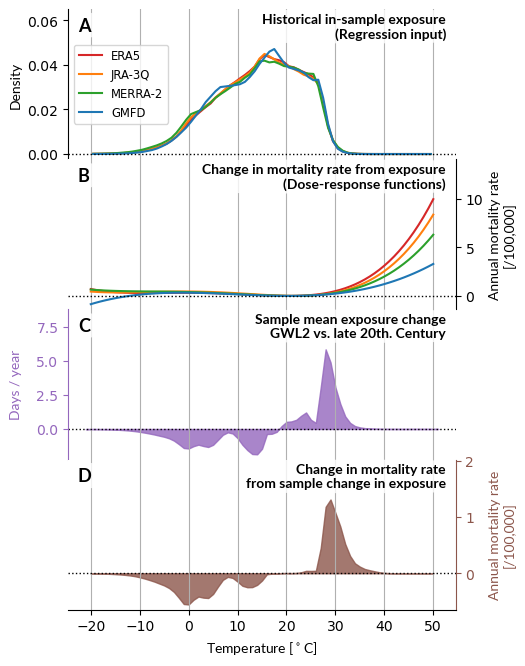

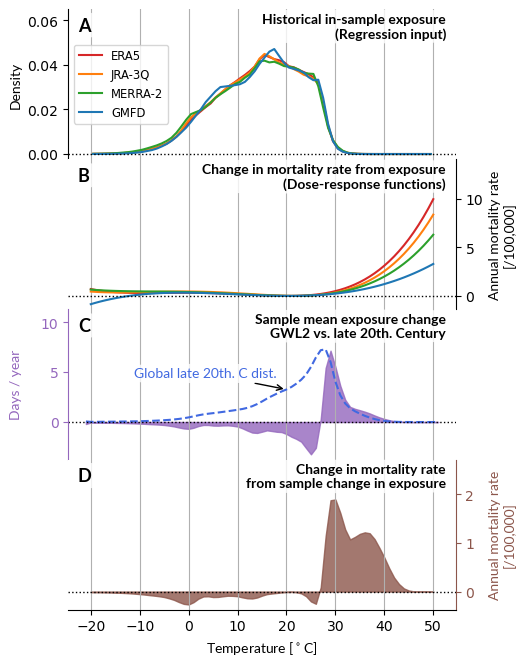

In [17]:
for insamp in [True,False]:
    if insamp:
        meantyp = 'popw_insamp'
    else:
        meantyp = 'popw'
    plot_data_all = [exposure_dists.sel(meantype='popw'),
                     dmgf,
                     #dmgf.std('proj_base'),
                     ds_bcd_agg['dmortality_mean'].sel(meantype=meantyp).mean('proj_base'),
                     ds_bcd_agg['dmortality_timpact'].sel(meantype=meantyp).mean('proj_base')]
    
    line_colors = [None,
                   None,
                   #'tab:pink',
                   'tab:purple',
                   'tab:brown']
    
    names = ['Historical in-sample exposure\n(Regression input)',
             'Change in mortality rate from exposure\n(Dose-response functions)',
             #'Std. dev across reanalyses\nof dose-response functions',
             'Sample mean exposure change\nGWL2 vs. late 20th. Century',
             'Change in mortality rate\nfrom sample change in exposure']
    
    
    ylabels = ['Density',
               'Annual mortality rate\n[/100,000]',#Mortality rate impact\n[/100,000]',
               #'Annual mortality rate\n[/100,000]',#'SD of mortality rate impact\n[/100,000]',
               'Days / year',
               'Annual mortality rate\n[/100,000]',#'Change in mortality rate\n[/100,000]']
              ]
    #colors = ['tab:red','tab:blue','tab:green','tab:orange']
    colors = ['darkviolet']*4
    
    colors_rea = {'ERA5':'tab:red',
                  'MERRA2':'tab:green',
                  'JRA-3Q':'tab:orange',
                  'GMFD':'tab:blue'}
    
    save_fig = True
    if insamp:
        output_fn = f'{dir_list['figs']}extra_figs/Figure1_long_insamp'
    else:
        output_fn = f'{dir_list['figs']}Figure1_long'
    
    n = len(plot_data_all)
    fig, axes = plt.subplots(n, 1, figsize=(5, 1.75 * n + 0.8),
                             sharex=True, gridspec_kw={'hspace': 0})
    
    
    for i, (ax, data) in enumerate(zip(axes, plot_data_all)):
        
        if 'proj_base' in data.sizes:
            data['proj_base'] = [re.sub(r'\-025','',pb) for pb in data.proj_base.values]
            for pb in ['ERA5','JRA-3Q','MERRA2','GMFD']:#data.proj_base.values; listing explicitly to keep order as if "reading down" the dmgfs 
                data.sel(proj_base=pb).plot(color=colors_rea[pb],
                                            label=re.sub(r'MERRA2','MERRA-2',re.sub(r'\-025','',pb)),
                                            ax=ax)
            color='k'
        else:
            color=line_colors[i]
            ax.fill_between(data.binC,
                            data.values,
                            color=color,alpha=0.8)
    
        if i == 0:
            ax.legend(fontsize='small',loc='center left')
    
        # Add pop-weighted GWL0.61 reference
        if (not insamp) and ('exposure change' in names[i]):
            plot_data_tmp = ds_bcd_agg['mortality0_mean'].sel(meantype='popw').mean('proj_base')
            plot_data_tmp = (plot_data_tmp / plot_data_tmp.max())*ax.get_ylim()[1]*0.95
            plot_data_tmp.plot(color='royalblue',linestyle='--',ax=ax)
    
            arrow_bin = 20
            plot_data_tmp.sel(binC=arrow_bin)
            
            ax.annotate('Global late 20th. C dist.',
                         (arrow_bin,plot_data_tmp.sel(binC=arrow_bin)),
                         (arrow_bin-2,plot_data_tmp.sel(binC=arrow_bin)+1),
                         va='bottom',ha='right',arrowprops = {'arrowstyle':'->'},
                         color='royalblue',
                        bbox = {'boxstyle':'round4','ec':'none','fc':'w','alpha':0.8},
                         font=extra_fonts['lato'])
            
        
        # Remove spines, keep relevant axis in color of plot
        ax.spines[['top','bottom']].set_visible(False)
        side = 'left' if i % 2 == 0 else 'right'
        #side = 'left'
        other = 'right' if side == 'left' else 'left'
        ax.spines[other].set_visible(False)
        ax.spines[side].set_color(color)
    
        ax.yaxis.set_label_position(side)
        ax.yaxis.set_ticks_position(side)
        ax.set_ylabel(ylabels[i], color=color,font=extra_fonts['lato'])
        ax.tick_params(axis="y", colors=color)
        ax.tick_params(axis="x", bottom=False, labelbottom=False)
    
        ax.grid(axis='x')
        ax.axhline(0,color='k',lw=1,linestyle=':')
        ax.set_title('')
    
        ylims = ax.get_ylim()
        ax.set_ylim(ylims[0],ylims[1]+(0.3*(ylims[1]-ylims[0])))
    
        ax.annotate(names[i],
                    (0.975,0.975),
                    xycoords='axes fraction',
                    va='top',ha='right',
                    font=extra_fonts['lato-bold'],
                    bbox = {'boxstyle':'round4','fc':'white','ec':'none','alpha':0.8})
    
        ax.annotate(subplot_lettering[i],
                    (0.025,0.95),xycoords = 'axes fraction',
                    bbox = {'boxstyle':'round4','fc':'white','ec':'none','alpha':0.8},
                    va='top',font=extra_fonts['lato-bold'],fontsize=13)
    
    # Nur die unterste Achse zeigt die x-Achse
    axes[-1].spines['bottom'].set_visible(True)
    axes[-1].tick_params(axis='x', bottom=True, labelbottom=True)
    axes[-1].set_xlabel(r'Temperature [$^\circ$C]',
                          font=extra_fonts['lato'])
    fig.align_ylabels(axes)
    
    if save_fig:
        utility_print(output_fn)

## Alternate versions with horizontal panels

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/extra_figs/Figure1_seppanels_wBCDSunc.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/extra_figs/Figure1_seppanels_wBCDSunc.png saved!


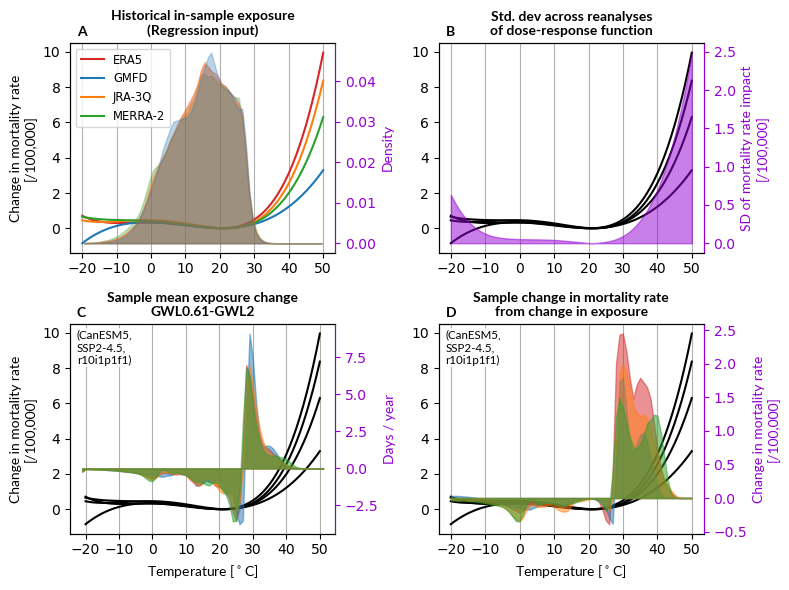

In [18]:
save_fig = True
output_fn = f'{dir_list['figs']}extra_figs/Figure1_seppanels_wBCDSunc'

plot_data_all = [exposure_dists.sel(meantype='popw'),
             dmgf.std('proj_base'),
             ds_bcd_agg['dmortality_mean'].sel(meantype='popw'),#.mean('proj_base'),
             ds_bcd_agg['dmortality_timpact'].sel(meantype='popw')]#.mean('proj_base')]

names = ['Historical in-sample exposure\n(Regression input)',
         'Std. dev across reanalyses\nof dose-response function',
         'Sample mean exposure change\nGWL0.61-GWL2',
         'Sample change in mortality rate\nfrom change in exposure']

ylabels = ['Density',
           'SD of mortality rate impact\n[/100,000]',
           'Days / year',
           'Change in mortality rate\n[/100,000]']

#colors = ['tab:red','tab:blue','tab:green','tab:orange']
colors = ['darkviolet']*4

colors_rea = {'ERA5':'tab:red',
              'MERRA2':'tab:green',
              'JRA-3Q':'tab:orange',
              'GMFD':'tab:blue'}

fig = plt.figure(figsize=(8,6))
for plt_idx,plot_data in enumerate(plot_data_all):
    ax = plt.subplot(2,2,plt_idx+1)

    ax.annotate(subplot_lettering[plt_idx],
                (0.025,1.025),xycoords = 'axes fraction',
                va='bottom',font=extra_fonts['lato-bold'])

    #----- Plot dose-response function
    for pb in dmgf.proj_base.values:
        if plt_idx == 0:
            dmgf.sel(proj_base=pb).plot(color=colors_rea[pb],label=re.sub(r'MERRA2','MERRA-2',re.sub(r'\-025','',pb)))
            exposure_alpha=0.3
            ax.legend(fontsize='small')
        else:
            dmgf.sel(proj_base=pb).plot(color='k')
            exposure_alpha=0.5
    if plt_idx in [0,2]:
        ax.set_ylabel('Change in mortality rate\n[/100,000]',
                      font=extra_fonts['lato'])
    else:
        ax.set_ylabel('')
    if plt_idx > 1:
        ax.set_xlabel(r'Temperature [$^\circ$C]',
                      font=extra_fonts['lato'])
    else:
        ax.set_xlabel('')

    ax.set_title(names[plt_idx],
                 font=extra_fonts['lato-bold'])

    ax.set_xticks(np.arange(-20,51,10))
    ax.grid(axis='x')

    if plt_idx > 1:
        id_parts = [str(ds_bcd[v].values) for v in ['model','experiment','run']]
        for idx in range(len(id_parts)):
            if re.search(r'^ssp',id_parts[idx]):
                id_parts[idx] = f'SSP{id_parts[idx][3]}-{id_parts[idx][4]}.{id_parts[idx][5]}'
        ax.annotate('('+',\n'.join(id_parts)+')',
                (0.025,0.975),xycoords = 'axes fraction',va='top',ha='left',fontsize='small',
                    bbox = {'facecolor':'w','edgecolor':'none','alpha':0.8,'pad':1},
                    font=extra_fonts['lato'])

    #----- Plot other data on second axis
    ax2 = ax.twinx()
    if 'proj_base' in plot_data_all[plt_idx].sizes:
        for pb in plot_data_all[plt_idx].proj_base.values:
            ax2.fill_between(plot_data_all[plt_idx].binC,
                             plot_data_all[plt_idx].sel(proj_base=pb).values,
                             color=colors_rea[re.sub(r'\-025','',pb)],alpha=exposure_alpha)
    else:
        ax2.fill_between(plot_data_all[plt_idx].binC,
                         plot_data_all[plt_idx].values,
                         color=colors[plt_idx],alpha=exposure_alpha)
    ax2.set_ylabel(ylabels[plt_idx],font=extra_fonts['lato'])
    ax2.set_xlabel('')
    ax2.set_title('')

    ax2.spines['right'].set_color(colors[plt_idx])
    ax2.tick_params(axis='y', colors=colors[plt_idx])
    ax2.yaxis.label.set_color(colors[plt_idx])

plt.tight_layout()

if save_fig:
    utility_print(output_fn)

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/extra_figs/Figure1_seppanels.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures_science/extra_figs/Figure1_seppanels.png saved!


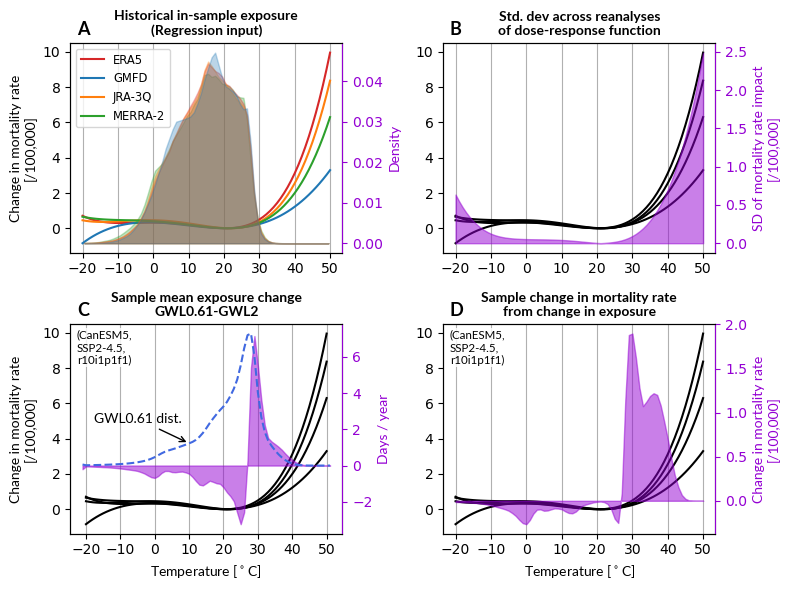

In [19]:
save_fig = True
output_fn = f'{dir_list['figs']}extra_figs/Figure1_seppanels'

plot_data_all = [exposure_dists.sel(meantype='popw'),
             dmgf.std('proj_base'),
             ds_bcd_agg['dmortality_mean'].sel(meantype='popw').mean('proj_base'),
             ds_bcd_agg['dmortality_timpact'].sel(meantype='popw').mean('proj_base')]

names = ['Historical in-sample exposure\n(Regression input)',
         'Std. dev across reanalyses\nof dose-response function',
         'Sample mean exposure change\nGWL0.61-GWL2',
         'Sample change in mortality rate\nfrom change in exposure']

ylabels = ['Density',
           'SD of mortality rate impact\n[/100,000]',
           'Days / year',
           'Change in mortality rate\n[/100,000]']

#colors = ['tab:red','tab:blue','tab:green','tab:orange']
colors = ['darkviolet']*4

colors_rea = {'ERA5':'tab:red',
              'MERRA2':'tab:green',
              'JRA-3Q':'tab:orange',
              'GMFD':'tab:blue'}

fig = plt.figure(figsize=(8,6))
for plt_idx,plot_data in enumerate(plot_data_all):
    ax = plt.subplot(2,2,plt_idx+1)

    ax.annotate(subplot_lettering[plt_idx],
                (0.025,1.025),xycoords = 'axes fraction',
                va='bottom',font=extra_fonts['lato-bold'],fontsize=13)

    #----- Plot dose-response function
    for pb in dmgf.proj_base.values:
        if plt_idx == 0:
            dmgf.sel(proj_base=pb).plot(color=colors_rea[pb],label=re.sub(r'MERRA2','MERRA-2',re.sub(r'\-025','',pb)))
            exposure_alpha=0.3
            ax.legend(fontsize='small')
        else:
            dmgf.sel(proj_base=pb).plot(color='k')
            exposure_alpha=0.5
    if plt_idx in [0,2]:
        ax.set_ylabel('Change in mortality rate\n[/100,000]',
                      font=extra_fonts['lato'])
    else:
        ax.set_ylabel('')
    if plt_idx > 1:
        ax.set_xlabel(r'Temperature [$^\circ$C]',
                      font=extra_fonts['lato'])
    else:
        ax.set_xlabel('')

    ax.set_title(names[plt_idx],
                 font=extra_fonts['lato-bold'])
    ax.set_xticks(np.arange(-20,51,10))
    ax.grid(axis='x')

    if plt_idx > 1:
        id_parts = [str(ds_bcd[v].values) for v in ['model','experiment','run']]
        for idx in range(len(id_parts)):
            if re.search(r'^ssp',id_parts[idx]):
                id_parts[idx] = f'SSP{id_parts[idx][3]}-{id_parts[idx][4]}.{id_parts[idx][5]}'
        ax.annotate('('+',\n'.join(id_parts)+')',
                (0.025,0.975),xycoords = 'axes fraction',va='top',ha='left',fontsize='small',
                    bbox = {'facecolor':'w','edgecolor':'none','alpha':0.8,'pad':1},
                    font=extra_fonts['lato'])

    #----- Plot other data on second axis
    ax2 = ax.twinx()
    if 'proj_base' in plot_data_all[plt_idx].sizes:
        for pb in plot_data_all[plt_idx].proj_base.values:
            ax2.fill_between(plot_data_all[plt_idx].binC,
                             plot_data_all[plt_idx].sel(proj_base=pb).values,
                             color=colors_rea[re.sub(r'\-025','',pb)],alpha=exposure_alpha)
    else:
        ax2.fill_between(plot_data_all[plt_idx].binC,
                         plot_data_all[plt_idx].values,
                         color=colors[plt_idx],alpha=exposure_alpha)

    # Add pop-weighted GWL0.61 reference
    if plt_idx == 2:
        plot_data_tmp = ds_bcd_agg['mortality0_mean'].sel(meantype='popw').mean('proj_base')
        plot_data_tmp = (plot_data_tmp / plot_data_tmp.max())*ax2.get_ylim()[1]*0.95
        plot_data_tmp.plot(color='royalblue',linestyle='--',ax=ax2)

        arrow_bin = 10
        plot_data_tmp.sel(binC=arrow_bin)
        
        ax2.annotate('GWL0.61 dist.',
                     (arrow_bin,plot_data_tmp.sel(binC=arrow_bin)),
                     (arrow_bin-2,plot_data_tmp.sel(binC=arrow_bin)+1),
                     va='bottom',ha='right',arrowprops = {'arrowstyle':'->'},
                     font=extra_fonts['lato'])
    
    ax2.set_ylabel(ylabels[plt_idx],font=extra_fonts['lato'])
    ax2.set_xlabel('')
    ax2.set_title('')

    ax2.spines['right'].set_color(colors[plt_idx])
    ax2.tick_params(axis='y', colors=colors[plt_idx])
    ax2.yaxis.label.set_color(colors[plt_idx])

    

plt.tight_layout()

if save_fig:
    utility_print(output_fn)

For simplicity, in panels c and d we show the mean across bias-correction and downscaling reanalysis ground truths for the sample BCD-ME member; though their exact distributions differ slighlty, the overwhelming majority of damages occur above 30$^\circ$C for all of them. 

In [ ]:
save_fig = True
output_fn = f'{dir_list['figs']}extra_figs/Figure1_seppanels_wide'

plot_data_all = [exposure_dists.sel(meantype='popw'),
             ds_bcd_agg['dmortality_mean'].sel(meantype='popw').mean('proj_base'),
             ds_bcd_agg['dmortality_timpact'].sel(meantype='popw').mean('proj_base')]

names = [r'Historical in-sample $T$ exposure'+'\n(Regression input)',
         r'Sample mean $T$ exposure change'+'\nGWL2 - GWL0.61',
         'Sample change in mortality rate\n'+r'from change in $T$ exposure']

ylabels = ['Density',
           'Days / year',
           'Change in mortality rate\n[/100,000]']

#colors = ['tab:red','tab:blue','tab:green','tab:orange']
colors = ['darkviolet']*4

colors_rea = {'ERA5':'tab:red',
              'MERRA2':'tab:green',
              'JRA-3Q':'tab:orange',
              'GMFD':'tab:blue'}

fig = plt.figure(figsize=(11,3))
for plt_idx,plot_data in enumerate(plot_data_all):
    ax = plt.subplot(1,3,plt_idx+1)

    ax.annotate(subplot_lettering[plt_idx],
                (0.025,1.025),xycoords = 'axes fraction',
                va='bottom',font=extra_fonts['lato-bold'],fontsize=13)

    #----- Plot dose-response function
    for pb in dmgf.proj_base.values:
        if plt_idx == 0:
            dmgf.sel(proj_base=pb).plot(color=colors_rea[pb],label=re.sub(r'MERRA2','MERRA-2',re.sub(r'\-025','',pb)))
            exposure_alpha=0.3
            ax.legend(fontsize='small')
        else:
            dmgf.sel(proj_base=pb).plot(color='k')
            exposure_alpha=0.5
    if plt_idx in [0]:
        ax.set_ylabel('Change in mortality rate\n[/100,000]',
                      font=extra_fonts['lato'])
    else:
        ax.set_ylabel('')
    ax.set_xlabel(r'Temperature [$^\circ$C]',
                      font=extra_fonts['lato'])

    ax.set_title(names[plt_idx],
                 font=extra_fonts['lato-bold'])
    ax.set_xticks(np.arange(-20,51,10))
    ax.grid(axis='x')

    if plt_idx > 0:
        id_parts = [str(ds_bcd[v].values) for v in ['model','experiment','run']]
        for idx in range(len(id_parts)):
            if re.search(r'^ssp',id_parts[idx]):
                id_parts[idx] = f'SSP{id_parts[idx][3]}-{id_parts[idx][4]}.{id_parts[idx][5]}'
        ax.annotate('('+',\n'.join(id_parts)+')',
                (0.025,0.975),xycoords = 'axes fraction',va='top',ha='left',fontsize='small',
                    bbox = {'facecolor':'w','edgecolor':'none','alpha':0.8,'pad':1},
                    font=extra_fonts['lato'])

    #----- Plot other data on second axis
    ax2 = ax.twinx()
    if 'proj_base' in plot_data_all[plt_idx].sizes:
        for pb in plot_data_all[plt_idx].proj_base.values:
            ax2.fill_between(plot_data_all[plt_idx].binC,
                             plot_data_all[plt_idx].sel(proj_base=pb).values,
                             color=colors_rea[re.sub(r'\-025','',pb)],alpha=exposure_alpha)
    else:
        ax2.fill_between(plot_data_all[plt_idx].binC,
                         plot_data_all[plt_idx].values,
                         color=colors[plt_idx],alpha=exposure_alpha)

    # Add pop-weighted GWL0.61 reference
    if plt_idx == 1:
        plot_data_tmp = ds_bcd_agg['mortality0_mean'].sel(meantype='popw').mean('proj_base')
        plot_data_tmp = (plot_data_tmp / plot_data_tmp.max())*ax2.get_ylim()[1]*0.95
        plot_data_tmp.plot(color='royalblue',linestyle='--',ax=ax2)

        arrow_bin = 10
        plot_data_tmp.sel(binC=arrow_bin)
        
        ax2.annotate('GWL0.61 dist.',
                     (arrow_bin,plot_data_tmp.sel(binC=arrow_bin)),
                     (arrow_bin-2,plot_data_tmp.sel(binC=arrow_bin)+1),
                     va='bottom',ha='right',arrowprops = {'arrowstyle':'->'},
                     color='royalblue',
                     font=extra_fonts['lato'])
    
    ax2.set_ylabel(ylabels[plt_idx],font=extra_fonts['lato'])
    ax2.set_xlabel('')
    ax2.set_title('')

    ax2.spines['right'].set_color(colors[plt_idx])
    ax2.tick_params(axis='y', colors=colors[plt_idx])
    ax2.yaxis.label.set_color(colors[plt_idx])

    

plt.tight_layout()

if save_fig:
    utility_print(output_fn)